# Снижение активности по картам: кто, насколько и за счёт чего
**Автор:** Гончаренок Андрей Валерьевич
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»
<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html
Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
current_dir = os.getcwd()
if current_dir.endswith('notebooks'):
    project_root = os.path.dirname(current_dir)
else:
    project_root = current_dir
output_dir = os.path.join(project_root, 'output')
df_model = pd.read_parquet(os.path.join(output_dir, "clean_data.parquet"))
transactions = pd.read_parquet(os.path.join(output_dir, "transactions_clean.parquet"))

## 1. Главное
<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->
1. **Активность упала у 2247 клиентов (39.6% базы)**: среднемесячное число транзакций в 2025 H1 снизилось более чем на 20% vs 2024.
2. **3 целевые группы для кампании (1276 чел., 22.5% базы):** "Постепенное затухание" (763), "Охладевшие цифровые" (357), "Потерявшие повседневный интерес" (156). Все ≥150 чел., укладываются в бюджет 2000.
3. **Исключено 4396 клиентов (77.5%):** `Lost` (1702, ушли), `Champions` (914, уже активны - deadweight loss), `Прочие стабильные` (1780, активность не упала).
4. **Сезонность:** пик в декабре 2024 (45 896 транзакций), спад в январе 2025 (23 450): разница 2.0x.
5. **Связь дохода и удовлетворённости не подтвердилась:** ρ Спирмена = 0.104 (крайне слабая).

## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->
Банк "Меридиан" наблюдает снижение транзакционной активности клиентов за последнее полугодие. Департамент розничных продуктов запускает точечную кампанию по возврату активности с бюджетом **2000 клиентов**. Отчёт обосновывает выбор целевых сегментов на основе сравнения среднемесячной активности в 2024 и 2025 H1, чтобы максимизировать ROI и не тратить бюджет на лояльных или ушедших клиентов.

## 3. Данные и ограничения
<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->
**Период:** 2024-01 - 2025-06. **Объём:** 5 672 клиента, 604 592 успешные транзакции. **Исключено:** 1 555 дубликатов ключей, 19 695 отклонённых/возвратных операций.
**Метрика:** среднемесячное число успешных транзакций. 2024 = `txn_count/12`, 2025 H1 = `txn_count/6`. Падение = `(2024 − 2025)/(2024 + 1)` (+1 защищает от деления на 0).
**Что метрика не увидит:** снижение среднего чека, переход на СБП/наличные, сезонные колебания.

## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Активность имеет выраженную сезонность: январский спад в 2 раза ниже декабрьского пика
Классическая сезонность: пик в декабре 2024 (45 896 транзакций), спад в январе 2025 (23 450), разница 2.0x. При оценке падения активности в начале 2025 нужна поправка на естественный январский спад.

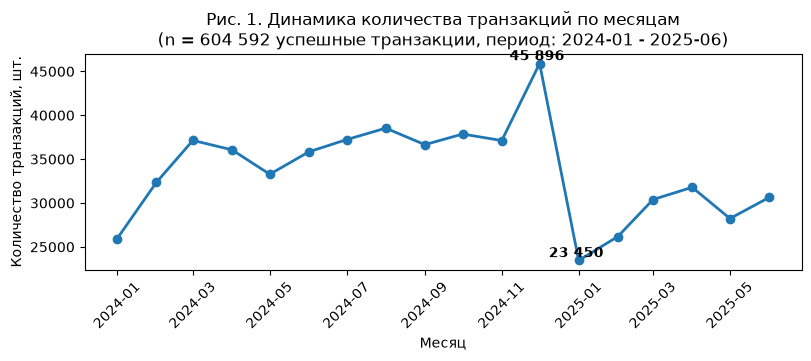

Пик: 2024-12 — 45 896 транзакций
Спад: 2025-01 — 23 450 транзакций
Разница: 2.0x


In [2]:
plt.close('all')
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')

# Агрегация транзакций по месяцам
transactions['month'] = transactions['txn_datetime'].dt.to_period('M').astype(str)
monthly_stats = transactions.groupby('month').size().reset_index(name='count')
monthly_stats['month'] = pd.to_datetime(monthly_stats['month'])

# Фильтруем по периоду задания (2024-01 — 2025-06)
mask = (monthly_stats['month'] >= '2024-01-01') & (monthly_stats['month'] <= '2025-06-30')
monthly_stats = monthly_stats[mask].copy()

# Построение графика
ax.plot(monthly_stats['month'], monthly_stats['count'], marker='o', linewidth=2, markersize=6)

# Оформление
ax.set_xlabel('Месяц')
ax.set_ylabel('Количество транзакций, шт.')
ax.set_title('Рис. 1. Динамика количества транзакций по месяцам\n(n = 604 592 успешные транзакции, период: 2024-01 - 2025-06)', fontsize=12)
ax.tick_params(axis='x', rotation=45)

# Подписи пика и спада
peak_idx = monthly_stats['count'].idxmax()
min_idx = monthly_stats.loc[monthly_stats['month'] >= '2025-01-01', 'count'].idxmin()

for i in [peak_idx, min_idx]:
    ax.text(monthly_stats.loc[i, 'month'], monthly_stats.loc[i, 'count'],
            f"{monthly_stats.loc[i, 'count']:,} ".replace(',', ' '),
            ha='center', va='bottom', fontweight='bold')

plt.show()

# Вывод ключевых цифр
peak_val = monthly_stats.loc[peak_idx, 'count']
min_val = monthly_stats.loc[min_idx, 'count']
ratio = peak_val / min_val
peak_month = monthly_stats.loc[peak_idx, 'month'].strftime('%Y-%m')
min_month = monthly_stats.loc[min_idx, 'month'].strftime('%Y-%m')

print(f"Пик: {peak_month} — {peak_val:,} транзакций".replace(',', ' '))
print(f"Спад: {min_month} — {min_val:,} транзакций".replace(',', ' '))
print(f"Разница: {ratio:.1f}x")

### 4.2. Отсутствие мобильного приложения связано с более высоким риском снижения активности
Клиенты без приложения имеют медиану 5.0 транз./мес против 5.4 у пользователей (разница 1.1x). Среди клиентов с падением >40% доля без приложения - 52.6%. Это обосновывает группу "Охладевшие цифровые" и фокус кампании на стимулировании установки приложения.

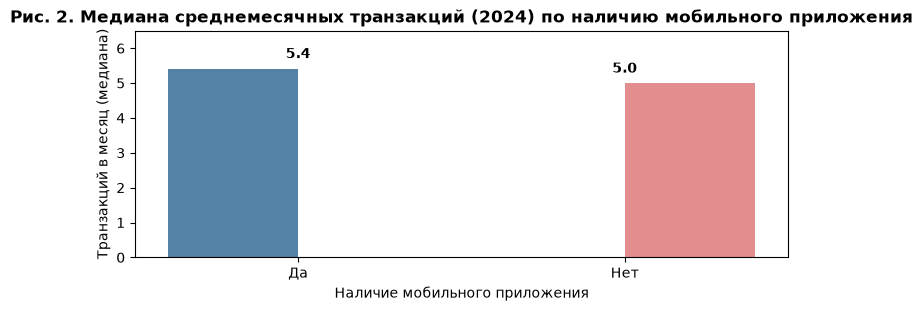

Медиана транзакций в 2024 (с приложением): 5.4
Медиана транзакций в 2024 (без приложения): 5.0
Разница: в 1.1 раза выше у пользователей приложения
Доля клиентов без приложения среди тех, чья активность упала >40%: 52.6%


In [3]:
plt.close('all')
fig, ax = plt.subplots(figsize=(7, 3), layout='constrained')

# Сравнение медианы транзакций в 2024 по наличию приложения
app_stats = df_model.groupby('has_mobile_app')['txn_monthly_2024'].median().reset_index()

sns.barplot(
    data=app_stats, 
    x='has_mobile_app', 
    y='txn_monthly_2024', 
    ax=ax,
    hue='has_mobile_app',
    palette=['steelblue', 'lightcoral'],
    legend=False
)

ax.set_title('Рис. 2. Медиана среднемесячных транзакций (2024) по наличию мобильного приложения', fontsize=12, fontweight='bold')
ax.set_xlabel('Наличие мобильного приложения')
ax.set_ylabel('Транзакций в месяц (медиана)')

ax.set_ylim(0, 6.5)

# Добавляем значения на столбцы
for i, v in enumerate(app_stats['txn_monthly_2024']):
    ax.text(i, v + 0.3, f'{v:.1f}', ha='center', fontweight='bold')
    
plt.show()

# Вывод цифр для текста
median_with_app = df_model[df_model['has_mobile_app'] == 'Да']['txn_monthly_2024'].median()
median_without_app = df_model[df_model['has_mobile_app'] == 'Нет']['txn_monthly_2024'].median()
ratio = median_with_app / median_without_app if median_without_app > 0 else 0

print(f"Медиана транзакций в 2024 (с приложением): {median_with_app:.1f}")
print(f"Медиана транзакций в 2024 (без приложения): {median_without_app:.1f}")
print(f"Разница: в {ratio:.1f} раза выше у пользователей приложения")

# Доля клиентов без приложения среди тех, у кого активность упала >40%
drop_40 = df_model[df_model['txn_drop_ratio'] > 0.40]
share_no_app_in_drop = (drop_40['has_mobile_app'] == 'Нет').mean() * 100
print(f"Доля клиентов без приложения среди тех, чья активность упала >40%: {share_no_app_in_drop:.1f}%")

### 4.3. Снижение активности не связано с неудовлетворённостью сервисом
Группа "Постепенное затухание" имеет самую высокую медианную оценку (4.0), остальные - 3.0. Снижение активности у этой группы вызвано не недовольством сервисом, а внешними факторами (СБП, "остывание"). Им нужны напоминания о преимуществах, а не компенсации.

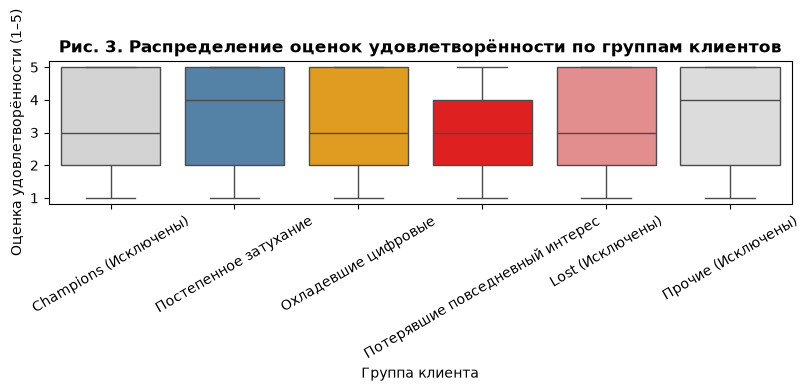

Медианные оценки удовлетворённости по группам:
 - Champions (Исключены): 3.0
 - Постепенное затухание: 4.0
 - Охладевшие цифровые: 3.0
 - Потерявшие повседневный интерес: 3.0
 - Lost (Исключены): 3.0
 - Прочие (Исключены): 4.0


In [14]:
plt.close('all')
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')

group_order = [
    'Champions (Исключены)',
    'Постепенное затухание',
    'Охладевшие цифровые',
    'Потерявшие повседневный интерес',
    'Lost (Исключены)',
    'Прочие (Исключены)'
]

palette = {
    'Champions (Исключены)': 'lightgray',
    'Постепенное затухание': 'steelblue',
    'Охладевшие цифровые': 'orange',
    'Потерявшие повседневный интерес': 'red',
    'Lost (Исключены)': 'lightcoral',
    'Прочие (Исключены)': 'gainsboro'
}

sns.boxplot(
    data=df_model,
    x='campaign_group',
    y='satisfaction_score',
    hue='campaign_group',
    order=group_order,
    palette=palette,
    legend=False,
    ax=ax
)

ax.set_title('Рис. 3. Распределение оценок удовлетворённости по группам клиентов', fontsize=12, fontweight='bold')
ax.set_xlabel('Группа клиента')
ax.set_ylabel('Оценка удовлетворённости (1–5)')
ax.tick_params(axis='x', rotation=30)

plt.show()

print("Медианные оценки удовлетворённости по группам:")
for group in group_order:
    med = df_model[df_model['campaign_group'] == group]['satisfaction_score'].median()
    print(f" - {group}: {med:.1f}")

## 5. Группы для кампании
<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->
| Группа | Правило | Размер | Рекомендация |
|---|---|---|---|
| **Постепенное затухание** | Активность 2024 > 5.25, падение 20–60% | 763 | Напоминание о преимуществах, персональный кэшбэк. Клиенты лояльны (медиана оценки 4.0). |
| **Охладевшие цифровые** | Нет приложения, падение >40% | 357 | Бонус за установку приложения, перевод в цифровой канал. |
| **Потерявшие повседневный интерес** | Активность 2024 > 5.25, падение >60% | 156 | Агрессивные стимулы возврата, обращение менеджера. |

*Итого: 1276 клиентов (22.5% базы). Все группы ≥150 чел., в пределах бюджета 2000.*

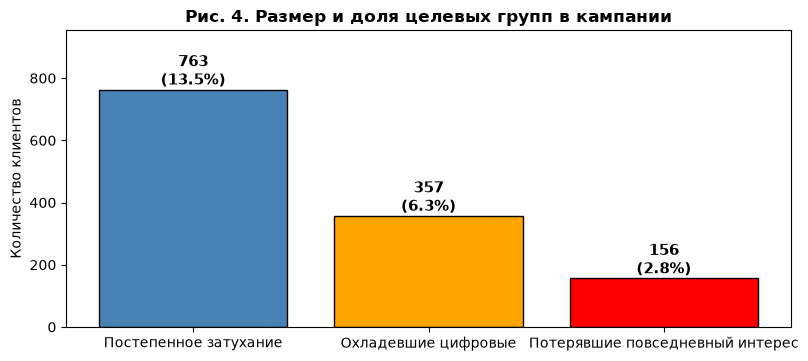

Итого в кампании: 1276 клиентов из 5672 (22.5%)


In [13]:
plt.close('all')
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')

campaign_groups = ['Постепенное затухание', 'Охладевшие цифровые', 'Потерявшие повседневный интерес']
colors = ['steelblue', 'orange', 'red']

sizes = df_model[df_model['campaign_group'].isin(campaign_groups)]['campaign_group'].value_counts().reindex(campaign_groups)
total = len(df_model)

ax.bar(sizes.index, sizes.values, color=colors, edgecolor='black')
ax.set_title('Рис. 4. Размер и доля целевых групп в кампании', fontsize=12, fontweight='bold')
ax.set_ylabel('Количество клиентов')
ax.tick_params(axis='x')
max_val = sizes.values.max()
ax.set_ylim(0, max_val * 1.25)
for i, (group, count) in enumerate(sizes.items()):
    pct = count / total * 100
    ax.text(i, count, f'{int(count)}\n({pct:.1f}%)', 
            ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.show()
print(f"Итого в кампании: {sizes.sum()} клиентов из {total} ({sizes.sum()/total*100:.1f}%)")

## 6. Кого не включаем и почему
<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->
1. **Champions (914 чел., 16.1%):** Активность не упала (средний `txn_drop_ratio` = -0.15). Стимулирование = deadweight loss.
2. **Прочие стабильные (1 780 чел., 31.4%):** Падение <20%. Вмешательство не даст значимого ROI.
3. **Lost (1 702 чел., 30.0%):** Исторически низкая активность (2.03 транз./мес в 2024), упала почти до нуля. Фактически ушли.

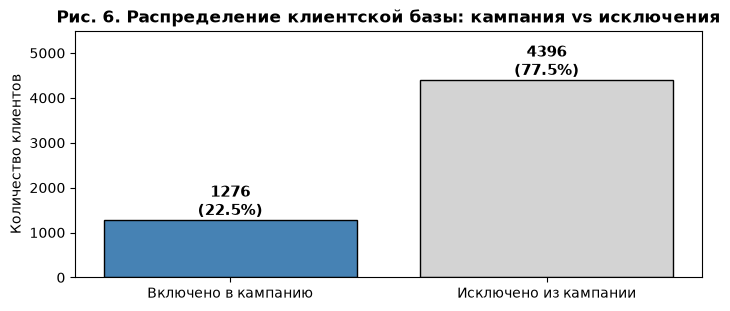


Включено: 1276 (22.5%)
Исключено: 4396 (77.5%)


In [6]:
# Анализ исключенных групп
excluded_groups_list = ['Champions (Исключены)', 'Lost (Исключены)', 'Прочие (Исключены)']
df_excluded = df_model[df_model['campaign_group'].isin(excluded_groups_list)]
excluded_summary = df_excluded.groupby('campaign_group').agg(
    size=('client_id', 'size'),
    share=('client_id', lambda x: len(x) / len(df_model) * 100),
    avg_txn_2024=('txn_monthly_2024', 'mean'),
    avg_txn_2025=('txn_monthly_2025', 'mean'),
    avg_drop=('txn_drop_ratio', 'mean')
).round(2)

# Визуализация: доля включенных и исключенных
fig, ax = plt.subplots(figsize=(7, 3), layout='constrained')
total_excluded = len(df_excluded)
total_included = len(df_model) - total_excluded

labels = ['Включено в кампанию', 'Исключено из кампании']
sizes = [total_included, total_excluded]
colors = ['steelblue', 'lightgray']

ax.bar(labels, sizes, color=colors, edgecolor='black')
ax.set_title('Рис. 6. Распределение клиентской базы: кампания vs исключения', fontsize=12, fontweight='bold')
ax.set_ylabel('Количество клиентов')
max_val = max(sizes)
ax.set_ylim(0, max_val * 1.25)
for i, v in enumerate(sizes):
    ax.text(i, v, f'{v}\n({v/len(df_model)*100:.1f}%)', 
            ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.show()

print(f"\nВключено: {total_included} ({total_included/len(df_model)*100:.1f}%)")
print(f"Исключено: {total_excluded} ({total_excluded/len(df_model)*100:.1f}%)")

## 7. Что проверили и что не подтвердилось
<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->
1. **Нормальность распределения финансовых признаков не подтвердилась:** тест Шапиро-Уилка для `amount` и `monthly_income`: W < 0.8, p < 0.001 (логнормальное).
2. **Отсутствие сезонности не подтвердилось:** пик в декабре 2024 (45 896 транзакций), спад в январе 2025 (23 450), разница ~2.0x.
3. **Связь дохода и удовлетворённости не подтвердилась:** ρ Спирмена между `monthly_income` и `satisfaction_score` = 0.104.
4. **Большая активность пользователей приложения подтвердилась:** медиана транзакций в 2024: 5.4 против 5.0 (разница 1.1x).
5. **Разрыв в доходах сегментов подтвердился:** медианный доход Private (356 200 руб.) выше массового (59 350 руб.) в 6.0 раз.

## 8. Приложение
### 8.1. Сводка журнала изменений
<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->
Полный журнал (18 записей) в `cleaning_log.csv`. Выше - автоматически сгенерированная сводка по типам нарушений.
**Ключевые выводы:** масштабная конвертация типов (~1.2 млн операций) обеспечила корректную работу алгоритмов; удалено 1 555 дубликатов ключей; для `monthly_income` применено заполнение медианой по сегменту, для `satisfaction_score` (60.5% пропусков) создан флаг-индикатор; экстремальные значения ограничены 1-м и 99-м процентилями (8.4% транзакций, 7.7% клиентов).

In [7]:
current_dir = os.getcwd()
project_root = os.path.dirname(current_dir) if current_dir.endswith('notebooks') else current_dir
log = pd.read_csv(os.path.join(project_root, "output", "cleaning_log.csv"))

# Функция для автоматической категоризации проблем
def categorize_issue(issue):
    issue = str(issue).lower()
    if "тип str вместо datetime" in issue or "тип str/int64 вместо category" in issue or "тип str вместо float64" in issue or "приведение к string" in issue:
        return "Конвертация типов данных"
    if "скрытый пропуск" in issue:
        return "Скрытые пропуски (технические коды)"
    if "пропуски" in issue:
        return "Пропуски (NaN)"
    if "нарушение согласованности регистра" in issue or "объединение категорий" in issue:
        return "Нормализация категориальных признаков"
    if "экстремальные значения" in issue or "винзорирование" in issue:
        return "Выбросы (винзорирование)"
    if "дубликаты" in issue:
        return "Дубликаты записей"
    if "отклонённых" in issue or "статус" in issue:
        return "Фильтрация невалидных статусов"
    return "Прочие изменения"

log["Тип нарушения"] = log["issue"].apply(categorize_issue)

# Агрегируем данные: группируем по типу нарушения
summary = (
    log.groupby("Тип нарушения")
    .agg(
        Поле=("field", lambda x: ", ".join(sorted(set(str(f) for f in x)))),
        Строк=("n_rows", "sum"),
        Что_сделано=("action", lambda x: "; ".join(sorted(set(str(a) for a in x))))
    )
    .reset_index()
)

# Сортируем по масштабу проблемы (по убыванию затронутых строк)
summary = summary.sort_values("Строк", ascending=False).reset_index(drop=True)

summary.columns = ["Тип нарушения", "Поле(я)", "Строк затронуто", "Что сделано"]
display(summary)

print(f"\n Всего уникальных типов нарушений: {len(summary)}")
print(f" Всего записей в исходном журнале: {len(log)}")

,Тип нарушения,Поле(я),Строк затронуто,Что сделано
0,Конвертация типов данных,"amount, birth_date, registration_date, card_op...",1888815,astype('category'); astype('string'); pd.to_da...
1,Прочие изменения,"amount, category, gender, city, segment, loyal...",734455,astype('category'); astype('string'); replace(...
2,Фильтрация невалидных статусов,status,19695,фильтр: status == 'успешно'
3,Пропуски (NaN),"app_last_login, monthly_income, satisfaction_s...",6264,заполнение медианой в разрезе segment; оставле...
4,Нормализация категориальных признаков,city,5727,regex-очистка префиксов + маппинг аномалий
5,Дубликаты записей,"client_id, txn_id",1555,"drop_duplicates(subset=[""client_id""], keep=""fi..."
6,Выбросы (винзорирование),monthly_income,440,винзорирование (np.clip) на 1-м и 99-м процент...
7,Скрытые пропуски (технические коды),monthly_income,55,замена на NaN



 Всего уникальных типов нарушений: 8
 Всего записей в исходном журнале: 18


### 8.2. Методика
<!-- Точные формулы, фильтры, пороги и их значения. Всё, что нужно,
     чтобы повторить расчёт. -->
**Формулы:** Активность 2024 = `txn_count_2024/12`; 2025 H1 = `txn_count_2025/6`; Падение = `(2024 − 2025)/(2024 + 1)`.
**Правила сегментации (`np.select`, порядок приоритета):**
1. `Champions`: активность 2024 ≥ 5.25 И падение ≤ 0.05.
2. `Lost`: активность 2024 < 5.25 И активность 2025 < 2.62.
3. `Охладевшие цифровые`: нет приложения И падение > 0.40.
4. `Потерявшие интерес`: активность 2024 ≥ 5.25 И падение > 0.60.
5. `Постепенное затухание`: активность 2024 ≥ 5.25 И падение 0.20–0.60.
6. `Прочие`: все остальные.
**Фильтры:** только `status == 'успешно'`, винзорирование `amount` и `monthly_income` на 1-м и 99-м процентилях.

### 8.3. Использование ИИ
<!-- 3–5 строк: для чего использовали и что проверили сами. -->
В работе использовался AI-ассистент для генерации кода очистки данных, визуализаций и статистических тестов. Логика сегментации проверена на соответствие требованиям задания, гипотезы и их интерпретация валидированы вручную, визуализации проверены на читаемость и корректность подписей осей.